In [217]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


In [218]:
working_directory = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [working_directory, *working_directory.parents]
        if (candidate / "data" / "raw" / "train").is_dir()
        and (candidate / "data" / "raw" / "student_test").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate a project root containing data/raw/train "
        "and data/raw/student_test from the current working directory."
    )

DATA_DIR = PROJECT_ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
TRAIN_DIR = RAW_DIR / "train"
TEST_DIR = RAW_DIR / "student_test"
PROCESSED_DIR = DATA_DIR / "processed"
CLEANED_DIR = PROCESSED_DIR / "cleaned"
FEATURE_DIR = PROCESSED_DIR / "features"
TRAIN_CLEANED_DIR = CLEANED_DIR / "train"
TEST_CLEANED_DIR = CLEANED_DIR / "student_test"
TRAIN_FEATURE_DIR = FEATURE_DIR / "train"
TEST_FEATURE_DIR = FEATURE_DIR / "student_test"
RESULTS_DIR = PROJECT_ROOT / "results"
PREPROCESSING_RESULTS_DIR = RESULTS_DIR / "preprocessing"

for directory in [
    TRAIN_CLEANED_DIR,
    TEST_CLEANED_DIR,
    TRAIN_FEATURE_DIR,
    TEST_FEATURE_DIR,
    PREPROCESSING_RESULTS_DIR,
]:
    directory.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Training directory:", TRAIN_DIR)
print("Student test directory:", TEST_DIR)
print("Processed directory:", PROCESSED_DIR)

Project root: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap
Training directory: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\data\raw\train
Student test directory: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\data\raw\student_test
Processed directory: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\data\processed


In [219]:
assert PROJECT_ROOT.exists(), "Project root does not exist."
assert TRAIN_DIR.exists(), "Training directory not found."
assert TEST_DIR.exists(), "Student test directory not found."

print("All required input directories exist.")


All required input directories exist.


In [220]:
def get_trip_directories(directory):

    return sorted(
        [
            folder
            for folder in directory.iterdir()
            if folder.is_dir()
        ]
    )


train_trips = get_trip_directories(TRAIN_DIR)
test_trips = get_trip_directories(TEST_DIR)

print("Training trips:", len(train_trips))
print("Student test trips:", len(test_trips))

print("\nSample training folders:")
for folder in train_trips[:5]:
    print(folder.name)

print("\nSample student test folders:")
for folder in test_trips[:5]:
    print(folder.name)
    

Training trips: 80
Student test trips: 10

Sample training folders:
00000001
00000002
00000003
00000004
00000005

Sample student test folders:
00000000
00000007
00000009
00000040
00000052


In [221]:
def _find_single_file(trip_folder, extension):
    matches = sorted(Path(trip_folder).glob(f"*.{extension}"))
    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one .{extension} file in {trip_folder}, "
            f"found {len(matches)}."
        )
    return matches[0]


def load_trip(trip_folder):
    trip_folder = Path(trip_folder)
    if not trip_folder.is_dir():
        raise FileNotFoundError(f"Trip folder does not exist: {trip_folder}")

    tables = {
        "track": ("track", ["longitude", "latitude", "timestamp"]),
        "nodes": ("nodes", ["longitude", "latitude"]),
        "arcs": ("arcs", ["from_node", "to_node"]),
        "route": ("route", ["arc_id"]),
    }
    loaded = {}
    for key, (extension, columns) in tables.items():
        file_path = _find_single_file(trip_folder, extension)
        frame = pd.read_csv(
            file_path,
            sep=r"\s+",
            header=None,
            names=columns,
            on_bad_lines="error",
        )
        if frame.empty:
            raise ValueError(f"Input file is empty: {file_path}")
        loaded[key] = frame

    loaded["track"]["observation_id"] = np.arange(len(loaded["track"]))
    loaded["nodes"]["node_id"] = np.arange(len(loaded["nodes"]))
    loaded["arcs"]["arc_id"] = np.arange(len(loaded["arcs"]))
    return {"trip_id": trip_folder.name, **loaded}


EARTH_RADIUS_M = 6_371_000.0
TIMESTAMP_TO_SECONDS = 1.0
MAX_SPEED_MPS = 55.0
SPIKE_BRIDGE_SPEED_RATIO = 0.5


def haversine_distance(lon1, lat1, lon2, lat2):
    lon1 = np.radians(np.asarray(lon1, dtype=float))
    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon2 = np.radians(np.asarray(lon2, dtype=float))
    lat2 = np.radians(np.asarray(lat2, dtype=float))
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    a = np.clip(a, 0, 1)
    return EARTH_RADIUS_M * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))


def detect_gps_anomalies(
    track,
    timestamp_to_seconds=TIMESTAMP_TO_SECONDS,
    speed_threshold_mps=MAX_SPEED_MPS,
    bridge_speed_ratio=SPIKE_BRIDGE_SPEED_RATIO,
):
    required = {"observation_id", "longitude", "latitude", "timestamp"}
    missing = required.difference(track.columns)
    if missing:
        raise ValueError(f"Track is missing required columns: {sorted(missing)}")

    df = track.copy().sort_values("observation_id", kind="stable").reset_index(drop=True)
    for column in ["longitude", "latitude", "timestamp"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

    count = len(df)
    timestamp = df["timestamp"].to_numpy(dtype=float)
    longitude = df["longitude"].to_numpy(dtype=float)
    latitude = df["latitude"].to_numpy(dtype=float)
    time_raw = np.diff(timestamp)
    time_seconds = time_raw * timestamp_to_seconds
    distances = np.full(max(count - 1, 0), np.nan)
    speeds = np.full(max(count - 1, 0), np.nan)

    if count > 1:
        distances = haversine_distance(
            longitude[:-1], latitude[:-1], longitude[1:], latitude[1:]
        )
        valid = np.isfinite(distances) & np.isfinite(time_seconds) & (time_seconds > 0)
        np.divide(distances, time_seconds, out=speeds, where=valid)

    df["distance_from_previous_m"] = np.r_[np.nan, distances]
    df["time_difference_raw"] = np.r_[np.nan, time_raw]
    df["time_difference_s"] = np.r_[np.nan, time_seconds]
    df["speed_mps"] = np.r_[np.nan, speeds]
    df["speed_kmh"] = df["speed_mps"] * 3.6
    df["above_speed_threshold"] = df["speed_mps"].gt(speed_threshold_mps)

    isolated_spikes = np.zeros(count, dtype=bool)
    if count >= 3:
        bridge_distance = haversine_distance(
            longitude[:-2], latitude[:-2], longitude[2:], latitude[2:]
        )
        bridge_time = (timestamp[2:] - timestamp[:-2]) * timestamp_to_seconds
        bridge_speed = np.full(count - 2, np.nan)
        valid_bridge = (
            np.isfinite(bridge_distance)
            & np.isfinite(bridge_time)
            & (bridge_time > 0)
        )
        np.divide(bridge_distance, bridge_time, out=bridge_speed, where=valid_bridge)
        incoming_speed = speeds[:-1]
        outgoing_speed = speeds[1:]
        isolated_spikes[1:-1] = (
            (incoming_speed > speed_threshold_mps)
            & (outgoing_speed > speed_threshold_mps)
            & (
                bridge_speed
                <= bridge_speed_ratio * np.minimum(incoming_speed, outgoing_speed)
            )
        )

    df["possible_gps_outlier"] = isolated_spikes
    return df


print("Trip loader and GPS diagnostics defined.")

Trip loader and GPS diagnostics defined.


In [222]:
sample_data = None
for trip_folder in train_trips:
    candidate = load_trip(trip_folder)
    if detect_gps_anomalies(candidate["track"])["possible_gps_outlier"].any():
        sample_data = candidate
        break

if sample_data is None:
    sample_data = load_trip(train_trips[0])

SAMPLE_TRIP_ID = sample_data["trip_id"]
track = sample_data["track"]
nodes = sample_data["nodes"]
arcs = sample_data["arcs"]
route = sample_data["route"]

print("Loaded sample trip:", SAMPLE_TRIP_ID)

Loaded sample trip: 00000033


In [223]:
print("GPS TRACK")
display(track.head())

print("\nROAD NETWORK NODES")
display(nodes.head())

print("\nROAD NETWORK ARCS")
display(arcs.head())

print("\nREFERENCE ROUTE")
display(route.head())


GPS TRACK


,longitude,latitude,timestamp,observation_id
0,18.718013,50.018685,1.0,0
1,18.717902,50.018761,2.0,1
2,18.717721,50.018835,3.0,2
3,18.717594,50.018838,4.0,3
4,18.717329,50.018912,5.0,4



ROAD NETWORK NODES


,longitude,latitude,node_id
0,18.687169,50.050970,0
1,18.691684,50.047784,1
2,18.692428,50.047045,2
3,18.689170,50.049864,3
4,18.686937,50.051378,4



ROAD NETWORK ARCS


,from_node,to_node,arc_id
0,0,5,0
1,0,3,1
2,0,2417,2
3,1,277,3
4,1,3031,4



REFERENCE ROUTE


,arc_id
0,5466
1,3500
2,3494
3,3185
4,3188


In [224]:
datasets = {
    "TRACK": track,
    "NODES": nodes,
    "ARCS": arcs,
    "ROUTE": route
}

for name, dataframe in datasets.items():

    print(f"\n{name}")
    print("-" * 40)

    print("Shape:", dataframe.shape)
    print("Data types:")

    display(dataframe.dtypes)
    


TRACK
----------------------------------------
Shape: (5844, 4)
Data types:


longitude         float64
latitude          float64
timestamp         float64
observation_id      int64
dtype: object


NODES
----------------------------------------
Shape: (3340, 3)
Data types:


longitude    float64
latitude     float64
node_id        int64
dtype: object


ARCS
----------------------------------------
Shape: (6360, 3)
Data types:


from_node    int64
to_node      int64
arc_id       int64
dtype: object


ROUTE
----------------------------------------
Shape: (169, 1)
Data types:


arc_id    int64
dtype: object

In [225]:
for name, dataframe in datasets.items():

    print(f"\n{name} missing values")

    display(
        dataframe.isnull().sum().to_frame(
            name="missing_count"
        )
    )
    


TRACK missing values


,missing_count
longitude,0
latitude,0
timestamp,0
observation_id,0



NODES missing values


,missing_count
longitude,0
latitude,0
node_id,0



ARCS missing values


,missing_count
from_node,0
to_node,0
arc_id,0



ROUTE missing values


,missing_count
arc_id,0


In [226]:
print(
    "Duplicate GPS coordinate-timestamp rows:",
    track.duplicated(
        subset=["longitude", "latitude", "timestamp"]
    ).sum()
)

print(
    "Duplicate road nodes:",
    nodes.duplicated(
        subset=["longitude", "latitude"]
    ).sum()
)

print(
    "Duplicate road arcs:",
    arcs.duplicated(
        subset=["from_node", "to_node"]
    ).sum()
)


Duplicate GPS coordinate-timestamp rows: 0
Duplicate road nodes: 0
Duplicate road arcs: 2


In [227]:
print("GPS longitude range:")
print(track["longitude"].min(), track["longitude"].max())

print("\nGPS latitude range:")
print(track["latitude"].min(), track["latitude"].max())

print("\nRoad-node longitude range:")
print(nodes["longitude"].min(), nodes["longitude"].max())

print("\nRoad-node latitude range:")
print(nodes["latitude"].min(), nodes["latitude"].max())


GPS longitude range:
18.694146 18.718013

GPS latitude range:
50.018685 50.045012

Road-node longitude range:
18.68419 18.728229

Road-node latitude range:
50.008608 50.055018


In [228]:
timestamp_difference = track["timestamp"].diff()

print("Timestamp statistics:")
display(timestamp_difference.describe())

print("\nFirst timestamp values:")
display(track["timestamp"].head(10))

print("\nNon-positive intervals:",
      (timestamp_difference <= 0).sum())

print("\nIntervals greater than 60:",
      (timestamp_difference > 60).sum())
      

Timestamp statistics:


count    5843.000000
mean        1.069998
std         0.256504
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max         3.000000
Name: timestamp, dtype: float64


First timestamp values:


0     1.0
1     2.0
2     3.0
3     4.0
4     5.0
5     7.0
6     8.0
7     9.0
8    10.0
9    11.0
Name: timestamp, dtype: float64


Non-positive intervals: 0

Intervals greater than 60: 0


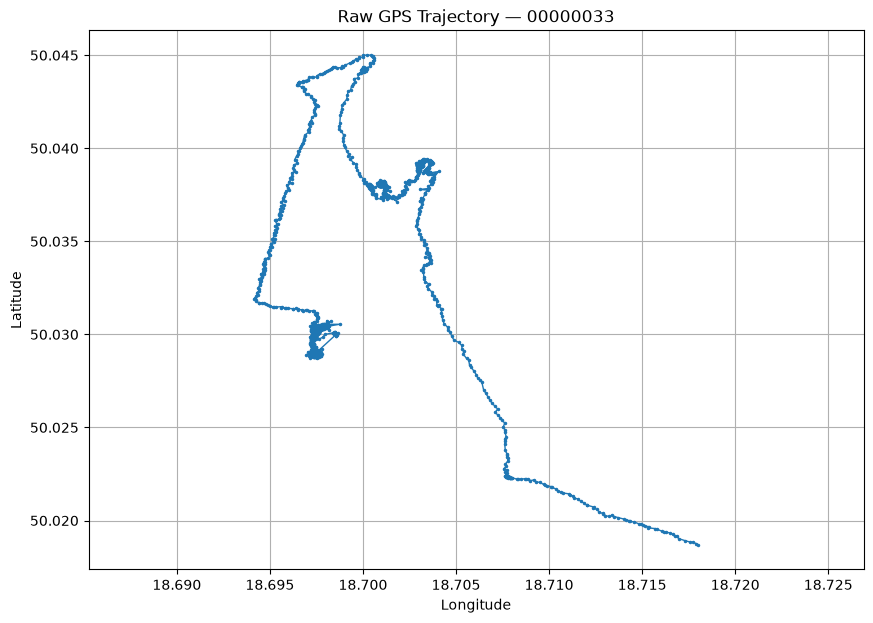

In [229]:
plt.figure(figsize=(10, 7))

plt.plot(
    track["longitude"],
    track["latitude"],
    marker=".",
    markersize=3,
    linewidth=1
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(f"Raw GPS Trajectory — {SAMPLE_TRIP_ID}")

plt.grid(True)
plt.axis("equal")
plt.show()

In [230]:
valid_node_ids = set(nodes["node_id"])

invalid_arc_references = (
    ~arcs["from_node"].isin(valid_node_ids)
    | ~arcs["to_node"].isin(valid_node_ids)
)

print("Invalid arc references:",
      invalid_arc_references.sum())

valid_arc_ids = set(arcs["arc_id"])

invalid_route_references = (
    ~route["arc_id"].isin(valid_arc_ids)
)

print("Invalid route references:",
      invalid_route_references.sum())
      

Invalid arc references: 0
Invalid route references: 0


In [231]:
def create_trip_inventory(trip_folders, partition):

    records = []

    for folder in trip_folders:

        data = load_trip(folder)

        records.append({
            "trip_id": data["trip_id"],
            "partition": partition,
            "gps_observations": len(data["track"]),
            "road_nodes": len(data["nodes"]),
            "road_arcs": len(data["arcs"]),
            "route_length": len(data["route"])
        })

    return records


inventory_records = []

inventory_records.extend(
    create_trip_inventory(train_trips, "train")
)

inventory_records.extend(
    create_trip_inventory(test_trips, "student_test")
)

dataset_inventory = pd.DataFrame(inventory_records)

display(dataset_inventory.head(10))

print("\nDataset summary:")
display(
    dataset_inventory.groupby("partition").agg(
        {
            "gps_observations": ["count", "mean", "min", "max"],
            "road_nodes": "mean",
            "road_arcs": "mean",
            "route_length": "mean"
        }
    )
)

dataset_inventory.to_csv(
    PREPROCESSING_RESULTS_DIR / "dataset_inventory.csv",
    index=False
)


,trip_id,partition,gps_observations,road_nodes,road_arcs,route_length
0,00000001,train,1315,88809,165790,525
1,00000002,train,7243,7936,16139,262
2,00000003,train,821,9138,18028,79
3,00000004,train,1064,7350,15499,320
4,00000005,train,1045,898,1579,105
5,00000006,train,1450,3259,6757,261
6,00000008,train,3093,4995,10421,173
7,00000010,train,2711,8502,15715,210
8,00000011,train,2828,2649,5393,565
9,00000012,train,1608,16376,38599,205



Dataset summary:


gps_observations                         road_nodes road_arcs  \
                        count       mean  min    max        mean      mean   
partition                                                                    
student_test               10  1916.0000  262   3958   9068.9000   18504.1   
train                      80  2605.2125  361  19313  24168.5625   48461.3   

             route_length  
                     mean  
partition                  
student_test        347.7  
train               391.7

DATA CLEANING AND VALIDATION

In [232]:
def clean_trip(data):
    track = data["track"].copy()
    nodes = data["nodes"].copy()
    arcs = data["arcs"].copy()
    route = data["route"].copy()

    audit = {
        "trip_id": data["trip_id"],
        "original_gps": len(track),
        "original_nodes": len(nodes),
        "original_arcs": len(arcs),
        "original_route": len(route),
    }

    for column in ["longitude", "latitude", "timestamp"]:
        track[column] = pd.to_numeric(track[column], errors="coerce")
    for column in ["longitude", "latitude"]:
        nodes[column] = pd.to_numeric(nodes[column], errors="coerce")
    for column in ["from_node", "to_node", "arc_id"]:
        arcs[column] = pd.to_numeric(arcs[column], errors="coerce")
    route["arc_id"] = pd.to_numeric(route["arc_id"], errors="coerce")

    track = track.replace([np.inf, -np.inf], np.nan)
    nodes = nodes.replace([np.inf, -np.inf], np.nan)
    arcs = arcs.replace([np.inf, -np.inf], np.nan)
    route = route.replace([np.inf, -np.inf], np.nan)

    missing_gps = track[["longitude", "latitude", "timestamp"]].isna().any(axis=1)
    audit["gps_missing_or_nonfinite_removed"] = int(missing_gps.sum())
    track = track.loc[~missing_gps].copy()

    invalid_coordinates = (
        ~track["longitude"].between(-180, 180)
        | ~track["latitude"].between(-90, 90)
    )
    audit["invalid_coordinates_removed"] = int(invalid_coordinates.sum())
    track = track.loc[~invalid_coordinates].copy()

    duplicate_gps = track.duplicated(
        subset=["longitude", "latitude", "timestamp"], keep="first"
    )
    audit["duplicate_gps_removed"] = int(duplicate_gps.sum())
    track = track.loc[~duplicate_gps].copy()
    track = track.sort_values("observation_id", kind="stable").reset_index(drop=True)

    time_difference = track["timestamp"].diff()
    audit["non_increasing_intervals"] = int((time_difference <= 0).sum())
    audit["large_intervals_over_60_raw_units"] = int(
        (time_difference > 60).sum()
    )

    diagnostics = detect_gps_anomalies(track)
    spike_ids = set(
        diagnostics.loc[
            diagnostics["possible_gps_outlier"], "observation_id"
        ]
    )
    spike_mask = track["observation_id"].isin(spike_ids)
    audit["isolated_gps_spikes_removed"] = int(spike_mask.sum())
    track = track.loc[~spike_mask].copy().reset_index(drop=True)

    valid_node_coordinates = (
        nodes["longitude"].between(-180, 180)
        & nodes["latitude"].between(-90, 90)
    )
    nodes["valid_coordinates"] = valid_node_coordinates
    audit["invalid_nodes_retained_for_id_stability"] = int(
        (~valid_node_coordinates).sum()
    )
    valid_node_ids = set(nodes.loc[valid_node_coordinates, "node_id"].astype(int))

    invalid_arcs = (
        arcs["arc_id"].isna()
        | arcs["from_node"].isna()
        | arcs["to_node"].isna()
        | ~arcs["from_node"].isin(valid_node_ids)
        | ~arcs["to_node"].isin(valid_node_ids)
    )
    audit["invalid_arcs_removed"] = int(invalid_arcs.sum())
    arcs = arcs.loc[~invalid_arcs].copy()
    arcs[["from_node", "to_node", "arc_id"]] = arcs[
        ["from_node", "to_node", "arc_id"]
    ].astype(int)

    original_arc_ids = set(
        pd.to_numeric(data["arcs"]["arc_id"], errors="coerce")
        .dropna()
        .astype(int)
    )
    cleaned_arc_ids = set(arcs["arc_id"])
    invalid_route = (
        route["arc_id"].isna()
        | ~route["arc_id"].isin(original_arc_ids)
        | ~route["arc_id"].isin(cleaned_arc_ids)
    )
    audit["invalid_route_references_removed"] = int(invalid_route.sum())
    route = route.loc[~invalid_route].copy()
    route["arc_id"] = route["arc_id"].astype(int)

    audit["cleaned_gps"] = len(track)
    audit["cleaned_nodes"] = len(nodes)
    audit["cleaned_arcs"] = len(arcs)
    audit["cleaned_route"] = len(route)
    cleaned_data = {
        "trip_id": data["trip_id"],
        "track": track,
        "nodes": nodes,
        "arcs": arcs,
        "route": route,
    }
    return cleaned_data, audit

In [233]:
cleaned_sample, sample_audit = clean_trip(sample_data)

print("Cleaning audit:")
display(pd.Series(sample_audit))

print("\nCleaned GPS:")
display(cleaned_sample["track"].head())

print("\nCleaned nodes:")
display(cleaned_sample["nodes"].head())

print("\nCleaned arcs:")
display(cleaned_sample["arcs"].head())

print("\nCleaned route:")
display(cleaned_sample["route"].head())

Cleaning audit:


trip_id                                    00000033
original_gps                                   5844
original_nodes                                 3340
original_arcs                                  6360
original_route                                  169
gps_missing_or_nonfinite_removed                  0
invalid_coordinates_removed                       0
duplicate_gps_removed                             0
non_increasing_intervals                          0
large_intervals_over_60_raw_units                 0
isolated_gps_spikes_removed                       1
invalid_nodes_retained_for_id_stability           0
invalid_arcs_removed                              0
invalid_route_references_removed                  0
cleaned_gps                                    5843
cleaned_nodes                                  3340
cleaned_arcs                                   6360
cleaned_route                                   169
dtype: object


Cleaned GPS:


,longitude,latitude,timestamp,observation_id
0,18.718013,50.018685,1.0,0
1,18.717902,50.018761,2.0,1
2,18.717721,50.018835,3.0,2
3,18.717594,50.018838,4.0,3
4,18.717329,50.018912,5.0,4



Cleaned nodes:


,longitude,latitude,node_id,valid_coordinates
0,18.687169,50.050970,0,True
1,18.691684,50.047784,1,True
2,18.692428,50.047045,2,True
3,18.689170,50.049864,3,True
4,18.686937,50.051378,4,True



Cleaned arcs:


,from_node,to_node,arc_id
0,0,5,0
1,0,3,1
2,0,2417,2
3,1,277,3
4,1,3031,4



Cleaned route:


,arc_id
0,5466
1,3500
2,3494
3,3185
4,3188


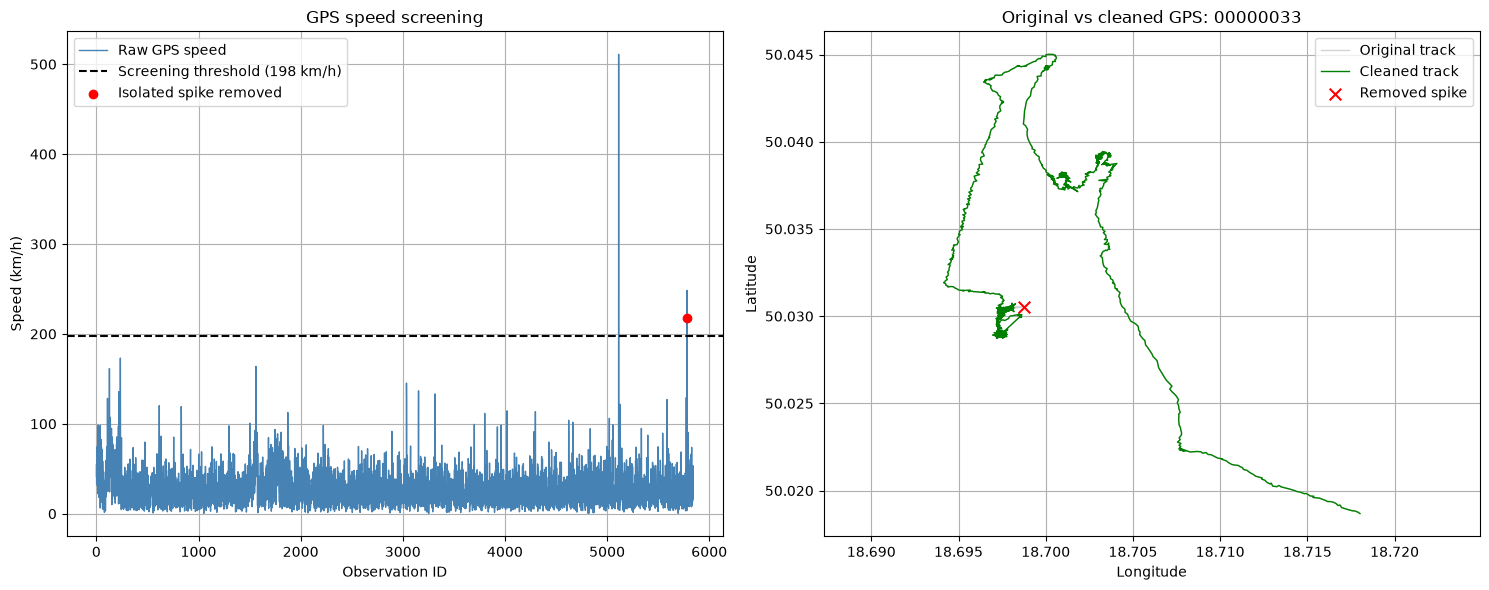

Isolated spikes removed: 1


In [234]:
sample_anomalies = detect_gps_anomalies(sample_data["track"])
candidate_points = sample_anomalies.loc[
    sample_anomalies["possible_gps_outlier"]
]
removed_ids = set(sample_data["track"]["observation_id"]) - set(
    cleaned_sample["track"]["observation_id"]
)
removed_points = sample_data["track"].loc[
    sample_data["track"]["observation_id"].isin(removed_ids)
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].plot(
    sample_anomalies["observation_id"],
    sample_anomalies["speed_kmh"],
    color="steelblue",
    linewidth=1,
    label="Raw GPS speed",
)
axes[0].axhline(
    MAX_SPEED_MPS * 3.6,
    color="black",
    linestyle="--",
    label=f"Screening threshold ({MAX_SPEED_MPS * 3.6:.0f} km/h)",
)
if not candidate_points.empty:
    axes[0].scatter(
        candidate_points["observation_id"],
        candidate_points["speed_kmh"],
        color="red",
        zorder=3,
        label="Isolated spike removed",
    )
axes[0].set_xlabel("Observation ID")
axes[0].set_ylabel("Speed (km/h)")
axes[0].set_title("GPS speed screening")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    sample_data["track"]["longitude"],
    sample_data["track"]["latitude"],
    color="lightgray",
    linewidth=1,
    label="Original track",
)
axes[1].plot(
    cleaned_sample["track"]["longitude"],
    cleaned_sample["track"]["latitude"],
    color="green",
    linewidth=1,
    label="Cleaned track",
)
if not removed_points.empty:
    axes[1].scatter(
        removed_points["longitude"],
        removed_points["latitude"],
        color="red",
        marker="x",
        s=70,
        label="Removed spike",
        zorder=4,
    )
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].set_title(f"Original vs cleaned GPS: {SAMPLE_TRIP_ID}")
axes[1].set_aspect("equal", adjustable="datalim")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()
print("Isolated spikes removed:", len(removed_points))

In [235]:
def save_cleaned_trip(data, output_directory):

    trip_output = output_directory / data["trip_id"]

    trip_output.mkdir(
        parents=True,
        exist_ok=True
    )

    data["track"].to_csv(
        trip_output / "track.csv",
        index=False
    )

    data["nodes"].to_csv(
        trip_output / "nodes.csv",
        index=False
    )

    data["arcs"].to_csv(
        trip_output / "arcs.csv",
        index=False
    )

    data["route"].to_csv(
        trip_output / "route.csv",
        index=False
    )


print("Cleaned-data saving function defined.")


Cleaned-data saving function defined.


In [236]:
cleaning_audits = []

for trip_folder in train_trips:

    data = load_trip(trip_folder)

    cleaned_data, audit = clean_trip(data)

    save_cleaned_trip(
        cleaned_data,
        TRAIN_CLEANED_DIR
    )

    audit["partition"] = "train"

    cleaning_audits.append(audit)


for trip_folder in test_trips:

    data = load_trip(trip_folder)

    cleaned_data, audit = clean_trip(data)

    save_cleaned_trip(
        cleaned_data,
        TEST_CLEANED_DIR
    )

    audit["partition"] = "student_test"

    cleaning_audits.append(audit)


cleaning_audit_df = pd.DataFrame(cleaning_audits)

display(cleaning_audit_df.head())

print("Trips cleaned:", len(cleaning_audit_df))


,trip_id,original_gps,original_nodes,original_arcs,original_route,gps_missing_or_nonfinite_removed,invalid_coordinates_removed,duplicate_gps_removed,non_increasing_intervals,large_intervals_over_60_raw_units,isolated_gps_spikes_removed,invalid_nodes_retained_for_id_stability,invalid_arcs_removed,invalid_route_references_removed,cleaned_gps,cleaned_nodes,cleaned_arcs,cleaned_route,partition
0,00000001,1315,88809,165790,525,0,0,0,0,0,0,0,0,0,1315,88809,165790,525,train
1,00000002,7243,7936,16139,262,0,0,0,0,5,0,0,0,0,7243,7936,16139,262,train
2,00000003,821,9138,18028,79,0,0,0,0,0,0,0,0,0,821,9138,18028,79,train
3,00000004,1064,7350,15499,320,0,0,0,0,0,0,0,0,0,1064,7350,15499,320,train
4,00000005,1045,898,1579,105,0,0,0,0,0,0,0,0,0,1045,898,1579,105,train


Trips cleaned: 90


In [237]:
cleaning_audit_df.to_csv(
    PREPROCESSING_RESULTS_DIR / "cleaning_audit.csv",
    index=False
)

print("Cleaning audit saved.")


Cleaning audit saved.


In [238]:
print("Cleaning audit columns:")
print(cleaning_audit_df.columns.tolist())

print("\nCleaning audit:")
display(cleaning_audit_df.head(10))

print("\nTotal cleaning audit:")
display(cleaning_audit_df.sum(numeric_only=True))

Cleaning audit columns:
['trip_id', 'original_gps', 'original_nodes', 'original_arcs', 'original_route', 'gps_missing_or_nonfinite_removed', 'invalid_coordinates_removed', 'duplicate_gps_removed', 'non_increasing_intervals', 'large_intervals_over_60_raw_units', 'isolated_gps_spikes_removed', 'invalid_nodes_retained_for_id_stability', 'invalid_arcs_removed', 'invalid_route_references_removed', 'cleaned_gps', 'cleaned_nodes', 'cleaned_arcs', 'cleaned_route', 'partition']

Cleaning audit:


,trip_id,original_gps,original_nodes,original_arcs,original_route,gps_missing_or_nonfinite_removed,invalid_coordinates_removed,duplicate_gps_removed,non_increasing_intervals,large_intervals_over_60_raw_units,isolated_gps_spikes_removed,invalid_nodes_retained_for_id_stability,invalid_arcs_removed,invalid_route_references_removed,cleaned_gps,cleaned_nodes,cleaned_arcs,cleaned_route,partition
0,00000001,1315,88809,165790,525,0,0,0,0,0,0,0,0,0,1315,88809,165790,525,train
1,00000002,7243,7936,16139,262,0,0,0,0,5,0,0,0,0,7243,7936,16139,262,train
2,00000003,821,9138,18028,79,0,0,0,0,0,0,0,0,0,821,9138,18028,79,train
3,00000004,1064,7350,15499,320,0,0,0,0,0,0,0,0,0,1064,7350,15499,320,train
4,00000005,1045,898,1579,105,0,0,0,0,0,0,0,0,0,1045,898,1579,105,train
5,00000006,1450,3259,6757,261,0,0,0,0,3,0,0,0,0,1450,3259,6757,261,train
6,00000008,3093,4995,10421,173,0,0,0,0,0,0,0,0,0,3093,4995,10421,173,train
7,00000010,2711,8502,15715,210,0,0,0,0,0,0,0,0,0,2711,8502,15715,210,train
8,00000011,2828,2649,5393,565,0,0,0,0,1,0,0,0,0,2828,2649,5393,565,train
9,00000012,1608,16376,38599,205,0,0,0,0,0,0,0,0,0,1608,16376,38599,205,train



Total cleaning audit:


original_gps                                227577
original_nodes                             2024174
original_arcs                              4061945
original_route                               34813
gps_missing_or_nonfinite_removed                 0
invalid_coordinates_removed                      0
duplicate_gps_removed                            0
non_increasing_intervals                         0
large_intervals_over_60_raw_units               70
isolated_gps_spikes_removed                      2
invalid_nodes_retained_for_id_stability          0
invalid_arcs_removed                             0
invalid_route_references_removed                 0
cleaned_gps                                 227575
cleaned_nodes                              2024174
cleaned_arcs                               4061945
cleaned_route                                34813
dtype: int64

In [239]:
print("Timestamp statistics:")

display(
    cleaning_audit_df[
        ["large_intervals_over_60_raw_units"]
    ].describe()
)

print("\nTrips with large timestamp intervals:")

display(
    cleaning_audit_df[
        cleaning_audit_df["large_intervals_over_60_raw_units"] > 0
    ]
)


Timestamp statistics:


,large_intervals_over_60_raw_units
count,90.000000
mean,0.777778
std,2.493938
min,0.000000
25%,0.000000
50%,0.000000
75%,0.750000
max,17.000000



Trips with large timestamp intervals:


,trip_id,original_gps,original_nodes,original_arcs,original_route,gps_missing_or_nonfinite_removed,invalid_coordinates_removed,duplicate_gps_removed,non_increasing_intervals,large_intervals_over_60_raw_units,isolated_gps_spikes_removed,invalid_nodes_retained_for_id_stability,invalid_arcs_removed,invalid_route_references_removed,cleaned_gps,cleaned_nodes,cleaned_arcs,cleaned_route,partition
1,00000002,7243,7936,16139,262,0,0,0,0,5,0,0,0,0,7243,7936,16139,262,train
5,00000006,1450,3259,6757,261,0,0,0,0,3,0,0,0,0,1450,3259,6757,261,train
8,00000011,2828,2649,5393,565,0,0,0,0,1,0,0,0,0,2828,2649,5393,565,train
11,00000014,448,4067,8288,164,0,0,0,0,1,0,0,0,0,448,4067,8288,164,train
16,00000021,15783,732,1510,277,0,0,0,0,2,0,0,0,0,15783,732,1510,277,train
18,00000024,801,25782,51609,249,0,0,0,0,2,0,0,0,0,801,25782,51609,249,train
22,00000028,3565,60628,127216,618,0,0,0,0,3,0,0,0,0,3565,60628,127216,618,train
33,00000041,1019,7837,14317,340,0,0,0,0,1,0,0,0,0,1019,7837,14317,340,train
34,00000042,7739,49376,101128,1440,0,0,0,0,17,0,0,0,0,7739,49376,101128,1440,train
35,00000043,2322,109070,215620,427,0,0,0,0,2,0,0,0,0,2322,109070,215620,427,train


In [240]:
print("Timestamp-gap audit (raw timestamp units):")
display(
    cleaning_audit_df["large_intervals_over_60_raw_units"].describe().to_frame()
)

print("Trips with gaps greater than 60 raw units:")
display(
    cleaning_audit_df.loc[
        cleaning_audit_df["large_intervals_over_60_raw_units"] > 0,
        ["trip_id", "large_intervals_over_60_raw_units", "partition"],
    ]
)

print(
    "These gaps are reported, not deleted: a long pause/gap alone "
    "does not prove a GPS fix is invalid."
)

Timestamp-gap audit (raw timestamp units):


,large_intervals_over_60_raw_units
count,90.000000
mean,0.777778
std,2.493938
min,0.000000
25%,0.000000
50%,0.000000
75%,0.750000
max,17.000000


Trips with gaps greater than 60 raw units:


,trip_id,large_intervals_over_60_raw_units,partition
1,00000002,5,train
5,00000006,3,train
8,00000011,1,train
11,00000014,1,train
16,00000021,2,train
18,00000024,2,train
22,00000028,3,train
33,00000041,1,train
34,00000042,17,train
35,00000043,2,train


These gaps are reported, not deleted: a long pause/gap alone does not prove a GPS fix is invalid.


In [241]:
total_before = int(cleaning_audit_df["original_gps"].sum())
total_after = int(cleaning_audit_df["cleaned_gps"].sum())
removed = total_before - total_after

print("Total GPS observations before:", f"{total_before:,}")
print("Total GPS observations after:", f"{total_after:,}")
print("Observations removed:", f"{removed:,}")
print(
    "Percentage removed:",
    round(removed / total_before * 100, 4) if total_before else 0,
    "%",
)

changed_trips = cleaning_audit_df.loc[
    cleaning_audit_df["original_gps"] != cleaning_audit_df["cleaned_gps"],
    [
        "trip_id",
        "original_gps",
        "cleaned_gps",
        "isolated_gps_spikes_removed",
        "partition",
    ],
]
print("Trips with GPS rows removed:", len(changed_trips))
display(changed_trips)

Total GPS observations before: 227,577
Total GPS observations after: 227,575
Observations removed: 2
Percentage removed: 0.0009 %
Trips with GPS rows removed: 2


,trip_id,original_gps,cleaned_gps,isolated_gps_spikes_removed,partition
26,00000033,5844,5843,1,train
68,00000085,1092,1091,1,train


In [242]:
expected_trip_ids = {folder.name for folder in train_trips + test_trips}
assert cleaning_audit_df["trip_id"].is_unique
assert set(cleaning_audit_df["trip_id"]) == expected_trip_ids
assert len(cleaning_audit_df) == len(expected_trip_ids)

for before_column, after_column in [
    ("original_gps", "cleaned_gps"),
    ("original_nodes", "cleaned_nodes"),
    ("original_arcs", "cleaned_arcs"),
    ("original_route", "cleaned_route"),
]:
    assert (cleaning_audit_df[after_column] <= cleaning_audit_df[before_column]).all()

clean_track = cleaned_sample["track"]
assert clean_track["observation_id"].is_unique
assert not clean_track.duplicated(
    subset=["longitude", "latitude", "timestamp"]
).any()
assert clean_track["longitude"].between(-180, 180).all()
assert clean_track["latitude"].between(-90, 90).all()
assert sample_audit["isolated_gps_spikes_removed"] == int(
    sample_anomalies["possible_gps_outlier"].sum()
)

print("Validation passed.")
print("Trips loaded and audited:", len(cleaning_audit_df))
print("GPS rows removed:", int(removed))
print(
    "Isolated GPS spikes removed:",
    int(cleaning_audit_df["isolated_gps_spikes_removed"].sum()),
)

Validation passed.
Trips loaded and audited: 90
GPS rows removed: 2
Isolated GPS spikes removed: 2


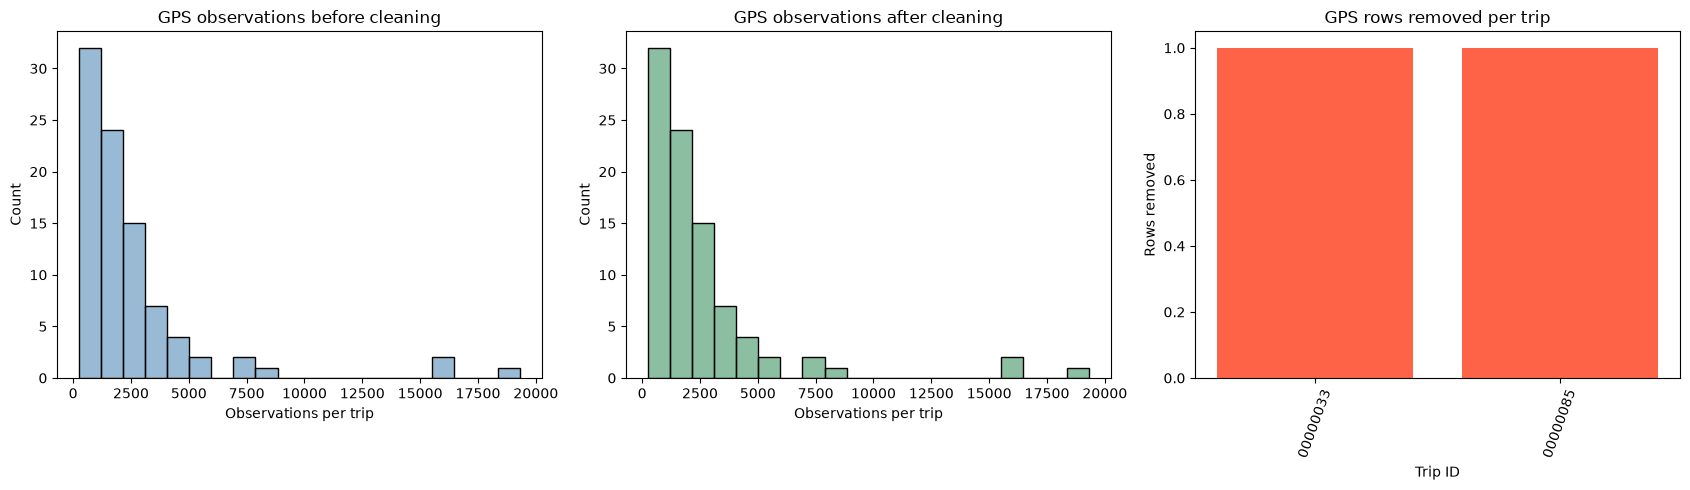

In [243]:
gps_counts = cleaning_audit_df[["original_gps", "cleaned_gps"]].to_numpy().ravel()
bin_edges = np.histogram_bin_edges(gps_counts, bins=20)
removed_per_trip = cleaning_audit_df["original_gps"] - cleaning_audit_df["cleaned_gps"]
changed = cleaning_audit_df.loc[removed_per_trip > 0].copy()
changed["gps_removed"] = removed_per_trip.loc[removed_per_trip > 0]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.histplot(cleaning_audit_df["original_gps"], bins=bin_edges, color="steelblue", alpha=0.55, ax=axes[0])
axes[0].set_title("GPS observations before cleaning")
axes[0].set_xlabel("Observations per trip")

sns.histplot(cleaning_audit_df["cleaned_gps"], bins=bin_edges, color="seagreen", alpha=0.55, ax=axes[1])
axes[1].set_title("GPS observations after cleaning")
axes[1].set_xlabel("Observations per trip")

if changed.empty:
    axes[2].text(0.5, 0.5, "No GPS rows removed", ha="center", va="center")
    axes[2].set_axis_off()
else:
    axes[2].bar(changed["trip_id"], changed["gps_removed"], color="tomato")
    axes[2].set_title("GPS rows removed per trip")
    axes[2].set_xlabel("Trip ID")
    axes[2].set_ylabel("Rows removed")
    axes[2].tick_params(axis="x", rotation=70)

plt.tight_layout()
plt.show()

## Candidate-edge features and training-ready tables



In [244]:
import importlib
import sys

source_directory = str(PROJECT_ROOT / "src")
if source_directory not in sys.path:
    sys.path.insert(0, source_directory)

import data.feature_engineering as feature_engineering
feature_engineering = importlib.reload(feature_engineering)
FEATURE_COLUMNS = feature_engineering.FEATURE_COLUMNS
prepare_model_data = feature_engineering.prepare_model_data

feature_audit = prepare_model_data(
    cleaned_root=CLEANED_DIR,
    output_root=FEATURE_DIR,
    validation_fraction=0.2,
    random_seed=42,
    max_candidates=32,
    nearest_samples=128,
    sample_spacing_m=30.0,
    label_radius_m=50.0,
    ambiguity_margin_m=5.0,
    timestamp_to_seconds=TIMESTAMP_TO_SECONDS,
)

training_trip_ids = set(
    feature_audit.loc[feature_audit["split"] == "train", "trip_id"]
)
validation_trip_ids = set(
    feature_audit.loc[feature_audit["split"] == "validation", "trip_id"]
)
assert training_trip_ids.isdisjoint(validation_trip_ids)
assert (
    set(feature_audit.loc[feature_audit["partition"] == "student_test", "split"])
    == {"student_test"}
)
assert set(FEATURE_COLUMNS).isdisjoint(
    {"candidate_arc_id", "label_distance_m", "label_margin_m", "route_geometry_suspect", "route_sequence_suspect", "route_sequence_consistent", "is_target"}
)

print("Feature columns:", FEATURE_COLUMNS)
print("Training trips:", len(training_trip_ids))
print("Validation trips:", len(validation_trip_ids))
print(
    "Minimum high-confidence candidate recall:",
    feature_audit.loc[
        feature_audit["partition"] == "train",
        "candidate_recall_high_confidence",
    ].min(),
)
display(
    feature_audit.groupby(["partition", "split"], as_index=False).agg(
        trips=("trip_id", "count"),
        gps_observations=("gps_observations", "sum"),
        candidate_rows=("candidate_rows", "sum"),
        supervised_observations=("supervised_observations", "sum"),
        geometry_suspect_trips=("route_geometry_suspect", "sum"),
        sequence_suspect_trips=("route_sequence_suspect", "sum"),
        sequence_labels_dropped=("route_sequence_labels_dropped", "sum"),
        median_label_distance_m=("median_label_distance_m", "median"),
        minimum_candidate_recall=("candidate_recall_high_confidence", "min"),
    )
)

quality_review = feature_audit.loc[
    feature_audit["route_geometry_suspect"]
    | feature_audit["route_sequence_suspect"]
    | (feature_audit["supervised_observations"] == 0),
    [
        "trip_id",
        "partition",
        "split",
        "route_geometry_suspect",
        "route_sequence_suspect",
        "high_confidence_labels",
        "ambiguous_high_confidence_labels",
        "candidate_recall_high_confidence",
        "route_sequence_labels_dropped",
        "supervised_observations",
    ],
]
display(quality_review)


train/00000001: 1,315 observations, 41,706 candidates, 1,033 supervised observations
train/00000002: 7,243 observations, 231,776 candidates, 3,148 supervised observations
train/00000003: 821 observations, 26,272 candidates, 587 supervised observations
train/00000004: 1,064 observations, 32,120 candidates, 748 supervised observations
train/00000005: 1,045 observations, 18,943 candidates, 980 supervised observations
train/00000006: 1,450 observations, 46,276 candidates, 485 supervised observations
train/00000008: 3,093 observations, 98,959 candidates, 1,381 supervised observations
train/00000010: 2,711 observations, 86,712 candidates, 1,203 supervised observations
train/00000011: 2,828 observations, 87,611 candidates, 0 supervised observations
train/00000012: 1,608 observations, 35,837 candidates, 1,460 supervised observations
train/00000013: 2,580 observations, 79,989 candidates, 2,070 supervised observations
train/00000014: 448 observations, 14,327 candidates, 246 supervised observatio

,partition,split,trips,gps_observations,candidate_rows,supervised_observations,geometry_suspect_trips,sequence_suspect_trips,sequence_labels_dropped,median_label_distance_m,minimum_candidate_recall
0,student_test,student_test,10,19160,553240,10496,0,1,644,4.598407,1.000000
1,train,train,64,179181,5268259,107306,1,1,792,4.718327,0.994181
2,train,validation,16,29234,908658,15456,1,0,74,4.424538,0.997087


,trip_id,partition,split,route_geometry_suspect,route_sequence_suspect,high_confidence_labels,ambiguous_high_confidence_labels,candidate_recall_high_confidence,route_sequence_labels_dropped,supervised_observations
8,00000011,train,train,False,False,2828,2828,1.000000,0,0
26,00000033,train,validation,True,False,2403,374,0.997087,8,0
44,00000054,train,train,True,True,2468,678,1.000000,269,0
85,00000056,student_test,student_test,False,True,3931,2183,1.000000,628,0


## Train and Compare Candidate-Road Models

This section compares Logistic Regression, Random Forest, Linear SVM, XGBoost, and KNN using trip-held-out validation data. The primary selection metric is observation-level Top-1 accuracy: for each GPS observation, it chooses the highest-scored road candidate and checks it against the reference segment. Route continuity and candidate-level F1 break ties. Student-test data is not used for model selection. Training is deterministically capped at 500 observations per training trip to keep memory bounded; SVM calibration uses a separate subset of training observation`s, and KNN uses at most 20 observations per trip.

In [1]:
from pathlib import Path
import sys

working_directory = Path.cwd().resolve()
root_candidates = [working_directory, *working_directory.parents]
root_candidates += [parent / 'PathSnap' for parent in root_candidates]
project_root = next(
    (candidate for candidate in root_candidates
     if (candidate / 'src' / 'models' / 'candidate_models.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not locate PathSnap/src/models/candidate_models.py from the notebook working directory.')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models.candidate_models import train_candidate_models

feature_root = project_root / 'data' / 'processed' / 'features'
cleaned_root = project_root / 'data' / 'processed' / 'cleaned'
model_output_root = project_root / 'results' / 'candidate_models'

model_comparison, best_model_name, best_model_path, model_run_summary = train_candidate_models(
    feature_root=feature_root,
    cleaned_root=cleaned_root,
    output_root=model_output_root,
    max_train_observations_per_trip=500,
    calibration_fraction=0.15,
    knn_observations_per_trip=20,
    random_seed=42,
)
display(model_comparison)
print(f'Best model by validation observation-level Top-1 accuracy: {best_model_name}')
print(f'Selected model saved to: {best_model_path}')
print(f'Run summary: {model_run_summary}')

Logistic Regression: top-1=0.8902, F1=0.7996, fit=1.0s, inference=0.1s
Random Forest: top-1=0.8984, F1=0.8785, fit=53.7s, inference=1.2s
Linear SVM: top-1=0.8907, F1=0.8003, fit=3.1s, inference=0.1s
XGBoost: top-1=0.8975, F1=0.8777, fit=6.7s, inference=0.4s
KNN: top-1=0.7635, F1=0.5715, fit=0.1s, inference=57.5s


,model,accuracy,precision,recall,f1,confusion_matrix,log_loss,observation_top1_accuracy,candidate_miss_rate,candidate_miss_count,...,sequence_order_consistency,sequence_exact_trip_rate,evaluated_observations,evaluated_candidate_rows,training_seconds,inference_seconds,training_observations,calibration_observations,knn_training_observations,classification_threshold
1,Random Forest,0.992088,0.888874,0.868401,0.878518,"[[452011, 1678], [2034, 13422]]",0.022355,0.898357,0.0,0,...,0.999687,0.0,15456,469145,53.667056,1.166575,23873,4216,NaN,0.5
3,XGBoost,0.991941,0.877856,0.877459,0.877657,"[[451802, 1887], [1894, 13562]]",0.020790,0.897451,0.0,0,...,0.999843,0.0,15456,469145,6.682547,0.407750,23873,4216,NaN,0.5
2,Linear SVM,0.987405,0.837899,0.765851,0.800257,"[[451399, 2290], [3619, 11837]]",0.033181,0.890722,0.0,0,...,0.999522,0.0,15456,469145,3.071048,0.135541,23873,4216,NaN,0.5
0,Logistic Regression,0.987375,0.838218,0.764299,0.799553,"[[451409, 2280], [3643, 11813]]",0.033192,0.890204,0.0,0,...,0.999681,0.0,15456,469145,1.009611,0.105655,23873,4216,NaN,0.5
4,KNN,0.978870,0.861013,0.427666,0.571478,"[[452622, 1067], [8846, 6610]]",0.075067,0.763522,0.0,0,...,0.984687,0.0,15456,469145,0.136345,57.537645,23873,4216,1240.0,0.5


Best model by validation observation-level Top-1 accuracy: Random Forest
Selected model saved to: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\results\candidate_models\best_model.joblib
Run summary: {'selection_metric': 'observation_top1_accuracy', 'selection_reason': 'It directly measures whether the highest-scored road candidate matches the reference segment for each GPS observation.', 'best_model': 'Random Forest', 'validation_trip_count': 16, 'training_trip_count': 64, 'max_train_observations_per_trip': 500, 'training_observations': 23873, 'calibration_observations': 4216, 'knn_observations_per_trip': 20, 'validation_observations': 15456, 'validation_candidate_rows': 469145, 'reliable_candidate_references': 15456, 'candidate_misses': 0, 'best_model_path': 'C:\\Users\\NIkAt\\coding\\codes\\Machine Learning\\ML_Hackathon\\PathSnap\\results\\candidate_models\\best_model.joblib', 'student_test_used_for_selection': False}


### Refit the Selected Model on All Training-Partition Trips

After selecting the model using the 64/16 train-validation split, refit only that model on the full training partition (80 trips, including the former validation trips). This uses no student-test features or labels. The deterministic per-trip cap remains in place for memory control; the 500-observation cap applies except for KNN, which remains capped at 20.

In [3]:
import gc
import json

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from src.models.candidate_models import _read_candidates
from xgboost import XGBClassifier

selection_bundle = joblib.load(best_model_path)
selected_model_name = selection_bundle['model_name']
training_audit = pd.read_csv(feature_root / 'feature_quality_audit.csv', dtype={'trip_id': str})
all_training_trip_ids = sorted(training_audit.loc[training_audit['partition'] == 'train', 'trip_id'].unique())
rng = np.random.default_rng(42)
features = selection_bundle['feature_columns']
train_columns = features + ['observation_id', 'supervision_usable', 'is_target']
fit_x_parts = []
fit_y_parts = []
calibration_x_parts = []
calibration_y_parts = []
final_refit_training_observations = 0
final_refit_calibration_observations = 0
final_refit_trip_ids = []

for trip_id in all_training_trip_ids:
    frame = _read_candidates(feature_root / 'train' / trip_id / 'candidates.csv.gz', train_columns)
    frame = frame.loc[frame['supervision_usable']]
    observation_ids = frame['observation_id'].drop_duplicates().to_numpy()
    if not len(observation_ids):
        continue
    observation_cap = 20 if selected_model_name == 'KNN' else 500
    selected_ids = np.sort(rng.choice(observation_ids, size=min(observation_cap, len(observation_ids)), replace=False))
    frame = frame.loc[frame['observation_id'].isin(selected_ids)]
    calibration_count = 0
    calibration_ids = set()
    if selected_model_name == 'Linear SVM' and len(selected_ids) >= 10:
        calibration_count = max(1, int(round(len(selected_ids) * 0.15)))
        shuffled_ids = rng.permutation(selected_ids)
        calibration_ids = set(shuffled_ids[:calibration_count])
    calibration_mask = frame['observation_id'].isin(calibration_ids).to_numpy()
    fit_mask = ~calibration_mask
    x = frame[features].to_numpy(dtype=np.float32)
    y = frame['is_target'].to_numpy(dtype=np.uint8)
    fit_x_parts.append(x[fit_mask])
    fit_y_parts.append(y[fit_mask])
    calibration_x_parts.append(x[calibration_mask])
    calibration_y_parts.append(y[calibration_mask])
    final_refit_training_observations += len(selected_ids) - calibration_count
    final_refit_calibration_observations += calibration_count
    final_refit_trip_ids.append(trip_id)
    del frame, x, y

if not fit_x_parts:
    raise ValueError('No usable labeled observations found in the full training partition.')
x_fit = np.concatenate(fit_x_parts)
y_fit = np.concatenate(fit_y_parts)
del fit_x_parts, fit_y_parts
final_scaler = StandardScaler(copy=False)
x_fit = final_scaler.fit_transform(x_fit).astype(np.float32, copy=False)
final_calibrator = None

if selected_model_name == 'Logistic Regression':
    final_estimator = LogisticRegression(C=1.0, max_iter=200, solver='lbfgs')
elif selected_model_name == 'Random Forest':
    final_estimator = RandomForestClassifier(n_estimators=50, max_depth=10, min_samples_leaf=10, max_features='sqrt', n_jobs=2, random_state=42)
elif selected_model_name == 'Linear SVM':
    if not calibration_x_parts:
        raise ValueError('Linear SVM final refit requires held-out training observations for calibration.')
    x_calibration = np.concatenate(calibration_x_parts)
    y_calibration = np.concatenate(calibration_y_parts)
    if np.unique(y_calibration).size != 2:
        raise ValueError('SVM calibration data must contain both classes.')
    x_calibration = final_scaler.transform(x_calibration).astype(np.float32, copy=False)
    final_estimator = LinearSVC(C=0.25, dual='auto', max_iter=3000, random_state=42)
elif selected_model_name == 'XGBoost':
    final_estimator = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=2.0, objective='binary:logistic', eval_metric='logloss', tree_method='hist', n_jobs=2, random_state=42)
elif selected_model_name == 'KNN':
    final_estimator = KNeighborsClassifier(n_neighbors=15, weights='distance', algorithm='kd_tree', leaf_size=40, n_jobs=2)
else:
    raise ValueError(f'Unsupported selected model for final refit: {selected_model_name}')

final_estimator.fit(x_fit, y_fit)
if selected_model_name == 'Linear SVM':
    calibration_scores = final_estimator.decision_function(x_calibration).reshape(-1, 1)
    final_calibrator = LogisticRegression(max_iter=200, solver='lbfgs')
    final_calibrator.fit(calibration_scores, y_calibration)

final_bundle = {
    'model_name': selected_model_name,
    'estimator': final_estimator,
    'scaler': final_scaler,
    'calibrator': final_calibrator,
    'feature_columns': features,
    'positive_class': True,
    'classification_threshold': 0.5,
    'final_refit_training_trip_count': len(final_refit_trip_ids),
    'final_refit_training_observations': final_refit_training_observations,
    'final_refit_calibration_observations': final_refit_calibration_observations,
}
joblib.dump(final_bundle, best_model_path)
selection_path = model_output_root / 'model_selection.json'
selection_summary = json.loads(selection_path.read_text(encoding='utf-8'))
selection_summary.update({
    'final_refit_training_partition': 'all training-partition trips after validation-based model selection',
    'final_refit_training_trip_count': len(final_refit_trip_ids),
    'final_refit_training_observations': final_refit_training_observations,
    'final_refit_calibration_observations': final_refit_calibration_observations,
    'final_refit_max_observations_per_trip': 20 if selected_model_name == 'KNN' else 500,
    'student_test_used_for_training': False,
})
selection_path.write_text(json.dumps(selection_summary, indent=2), encoding='utf-8')
print(f'Refit {selected_model_name} on {len(final_refit_trip_ids)} training-partition trips and {final_refit_training_observations:,} sampled observations.')
print(f'Updated final model: {best_model_path}')
del x_fit, y_fit, calibration_x_parts, calibration_y_parts
_ = gc.collect()


Refit Random Forest on 77 training-partition trips and 35,518 sampled observations.
Updated final model: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\results\candidate_models\best_model.joblib


### Final Evaluation on the Separate Student-Test Partition


In [4]:
import time

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, log_loss, precision_score, recall_score
from src.models.candidate_models import _probabilities, _read_candidates, _route_scores

best_bundle = joblib.load(best_model_path)
test_audit = pd.read_csv(feature_root / 'feature_quality_audit.csv', dtype={'trip_id': str})
test_trip_ids = sorted(test_audit.loc[test_audit['partition'] == 'student_test', 'trip_id'].unique())
test_columns = best_bundle['feature_columns'] + [
    'observation_id', 'candidate_arc_id', 'supervision_usable', 'is_target',
    'label_confident', 'label_unambiguous', 'candidate_label_found',
    'route_geometry_suspect', 'route_sequence_suspect', 'route_sequence_consistent',
]
test_frames = []
test_arc_endpoints = {}
test_route_positions = {}
test_candidate_misses = 0
test_reference_count = 0
unscored_test_trips = []

for trip_id in test_trip_ids:
    candidates_path = feature_root / 'student_test' / trip_id / 'candidates.csv.gz'
    frame = _read_candidates(candidates_path, test_columns)
    observation_metadata = frame.drop_duplicates('observation_id')
    reliable_reference = (
        observation_metadata['label_confident']
        & observation_metadata['label_unambiguous']
        & observation_metadata['route_sequence_consistent']
        & ~observation_metadata['route_geometry_suspect']
        & ~observation_metadata['route_sequence_suspect']
    )
    test_reference_count += int(reliable_reference.sum())
    test_candidate_misses += int((reliable_reference & ~observation_metadata['candidate_label_found']).sum())
    usable = frame.loc[frame['supervision_usable']].copy()
    if usable.empty:
        unscored_test_trips.append(trip_id)
        continue
    usable['trip_id'] = trip_id
    test_frames.append(usable[best_bundle['feature_columns'] + ['trip_id', 'observation_id', 'candidate_arc_id', 'is_target']].reset_index(drop=True))
    arc_table = pd.read_csv(cleaned_root / 'student_test' / trip_id / 'arcs.csv', usecols=['arc_id', 'from_node', 'to_node'])
    test_arc_endpoints[trip_id] = {int(row.arc_id): (int(row.from_node), int(row.to_node)) for row in arc_table.itertuples(index=False)}
    route_ids = pd.read_csv(cleaned_root / 'student_test' / trip_id / 'route.csv', usecols=['arc_id'])['arc_id'].to_numpy(dtype=int)
    test_route_positions[trip_id] = {}
    for position, arc_id in enumerate(route_ids):
        test_route_positions[trip_id].setdefault(int(arc_id), position)

if not test_frames:
    raise ValueError('No usable labeled observations were found in the student-test partition.')
test_y_parts = []
test_probability_parts = []
test_top_prediction_parts = []
test_inference_seconds = 0.0
for frame in test_frames:
    start = time.perf_counter()
    probabilities = _probabilities(
        {'name': best_bundle['model_name'], 'estimator': best_bundle['estimator'], 'calibrator': best_bundle['calibrator']},
        frame, best_bundle['scaler'], best_bundle['feature_columns'],
    )
    test_inference_seconds += time.perf_counter() - start
    test_y_parts.append(frame['is_target'].to_numpy(dtype=np.uint8))
    test_probability_parts.append(probabilities.astype(np.float32, copy=False))
    score_frame = pd.DataFrame({'observation_id': frame['observation_id'].to_numpy(), 'score': probabilities})
    top_indices = score_frame.groupby('observation_id', sort=False)['score'].idxmax().to_numpy(dtype=int)
    top = frame.iloc[top_indices][['trip_id', 'observation_id', 'candidate_arc_id', 'is_target']].copy()
    top['is_correct'] = top['is_target'].astype(bool)
    test_top_prediction_parts.append(top)

test_y_true = np.concatenate(test_y_parts)
test_probabilities = np.concatenate(test_probability_parts).astype(float)
test_predictions = test_probabilities >= 0.5
test_top_predictions = pd.concat(test_top_prediction_parts, ignore_index=True)
test_continuity, test_sequence_order, test_sequence_exact = _route_scores(
    test_top_predictions, test_arc_endpoints, test_route_positions
)
best_model_test_metrics = {
    'selected_model': best_bundle['model_name'],
    'scored_test_trips': len(test_frames),
    'unscored_test_trips': ', '.join(unscored_test_trips),
    'accuracy': accuracy_score(test_y_true, test_predictions),
    'precision': precision_score(test_y_true, test_predictions, zero_division=0),
    'recall': recall_score(test_y_true, test_predictions, zero_division=0),
    'f1': f1_score(test_y_true, test_predictions, zero_division=0),
    'confusion_matrix': confusion_matrix(test_y_true, test_predictions, labels=[0, 1]).tolist(),
    'log_loss': log_loss(test_y_true, np.clip(test_probabilities, 1e-7, 1 - 1e-7), labels=[0, 1]),
    'observation_top1_accuracy': float(test_top_predictions['is_correct'].mean()),
    'candidate_miss_rate': test_candidate_misses / test_reference_count if test_reference_count else float('nan'),
    'candidate_misses': test_candidate_misses,
    'reliable_reference_observations': test_reference_count,
    'route_continuity': test_continuity,
    'sequence_order_consistency': test_sequence_order,
    'sequence_exact_trip_rate': test_sequence_exact,
    'evaluated_observations': int(sum(frame['observation_id'].nunique() for frame in test_frames)),
    'evaluated_candidate_rows': int(len(test_y_true)),
    'inference_seconds': test_inference_seconds,
    'model_selection_used_test_data': False,
}
test_metrics_path = model_output_root / 'best_model_test_metrics.csv'
pd.Series(best_model_test_metrics, name='student_test').to_csv(test_metrics_path, header=True)
display(pd.Series(best_model_test_metrics, name='student_test').to_frame())
print(f'Final test metrics saved to: {test_metrics_path}')

,student_test
selected_model,Random Forest
scored_test_trips,9
unscored_test_trips,00000056
accuracy,0.990498
precision,0.901391
recall,0.839558
f1,0.869376
confusion_matrix,"[[267210, 964], [1684, 8812]]"
log_loss,0.026813
observation_top1_accuracy,0.893388


Final test metrics saved to: C:\Users\NIkAt\coding\codes\Machine Learning\ML_Hackathon\PathSnap\results\candidate_models\best_model_test_metrics.csv


## Next: Bayesian Optimization and HMM Route Reconstruction

Continue with the [02_Bayesian_Optimization_and_HMM_Route_Reconstruction.ipynb](./02_Bayesian_Optimization_and_HMM_Route_Reconstruction.ipynb) notebook. It tunes the selected Random Forest on validation trips and applies HMM/Viterbi route reconstruction without using the student-test set for selection.